# Data Understanding and Preparation

**Course:** Data Mining: Fundamental — University of Pisa (A.Y. 2026/2027)
**Dataset:** Seller-Level Vehicle Listings (`seller_info_dm1_2627.csv`)
**Goal of this notebook:** understand the data, clean it, prepare it, and export a
clean dataset ready to be consumed by the next steps (clustering, classification, regression).

The target variable is `seller_rating_class` (discretized seller rating: `low` / `medium` / `high`).

> Scope: this notebook stops at **Data Preparation & EDA**. No models are trained here.


## 0. Setup and imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler

## 1.1 Data Semantics

### 1.1.1 Load dataset & general overview

One row per seller (`sp_id`), summarising the vehicle listings observed for that seller.


In [2]:
df = pd.read_csv('dataset/seller_info_dm1_2627.csv')
df.head()

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,...,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,...,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,...,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,...,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,...,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,...,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium


In [3]:
# Column count by role
df.info(show_counts=True)   

<class 'pandas.DataFrame'>
RangeIndex: 13843 entries, 0 to 13842
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   sp_id                        13843 non-null  float64
 1   n_listings                   13843 non-null  int64  
 2   price_median                 13843 non-null  float64
 3   savings_amount_median        13843 non-null  float64
 4   daysonmarket_median          13843 non-null  float64
 5   mileage_median               13842 non-null  float64
 6   year_median                  13843 non-null  float64
 7   vehicle_age_median           13842 non-null  float64
 8   owner_count_median           13804 non-null  float64
 9   horsepower_median            13837 non-null  float64
 10  engine_displacement_median   10450 non-null  float64
 11  city_fuel_economy_median     13827 non-null  float64
 12  highway_fuel_economy_median  13827 non-null  float64
 13  back_legroom_median        

In [4]:
# Missing values count and percentage
missing = df.isnull().sum()
missing = missing[missing > 0]

pd.DataFrame(
    {"Missing Count": missing, "Percentage": (missing / len(df) * 100).round(2)}
).sort_values(by="Missing Count", ascending=False)

,Missing Count,Percentage
dominant_wheel_system,10518,75.98
engine_displacement_median,3393,24.51
owner_count_median,39,0.28
pct_salvage,27,0.20
pct_theft_title,27,0.20
pct_isCab,27,0.20
back_legroom_median,19,0.14
highway_fuel_economy_median,16,0.12
city_fuel_economy_median,16,0.12
front_legroom_median,7,0.05


### 1.1.2 Semantic description table

Each variable's meaning, the datatype it was read as, and its measurement scale.


In [5]:
semantics = [
    ('sp_id', 'Unique identifier of the seller/dealer', 'float64', 'Identifier (nominal)'),
    ('n_listings', 'Total number of vehicle listings of the seller (count)', 'int64', 'Ratio (count)'),
    ('price_median', 'Median advertised price of listed vehicles (USD)', 'float64', 'Ratio'),
    ('savings_amount_median', 'Median advertised savings amount (USD)', 'float64', 'Ratio'),
    ('daysonmarket_median', 'Median days vehicles remained on market (days)', 'float64', 'Ratio'),
    ('mileage_median', 'Median mileage of listed vehicles (miles)', 'float64', 'Ratio'),
    ('year_median', 'Median model year of listed vehicles (year)', 'float64', 'Interval (year)'),
    ('vehicle_age_median', 'Median age of vehicles at listing time (years)', 'float64', 'Ratio'),
    ('owner_count_median', 'Median number of previous owners (count)', 'float64', 'Ratio (count)'),
    ('horsepower_median', 'Median horsepower (hp)', 'float64', 'Ratio'),
    ('engine_displacement_median', 'Median engine displacement (cc)', 'float64', 'Ratio'),
    ('city_fuel_economy_median', 'Median city fuel economy (mpg)', 'float64', 'Ratio'),
    ('highway_fuel_economy_median', 'Median highway fuel economy (mpg)', 'float64', 'Ratio'),
    ('back_legroom_median', 'Median rear-seat legroom (in)', 'float64', 'Ratio'),
    ('front_legroom_median', 'Median front-seat legroom (in)', 'float64', 'Ratio'),
    ('fuel_tank_volume_median', 'Median fuel-tank capacity (gal)', 'float64', 'Ratio'),
    ('height_median', 'Median vehicle height (in)', 'float64', 'Ratio'),
    ('length_median', 'Median vehicle length (in)', 'float64', 'Ratio'),
    ('width_median', 'Median vehicle width (in)', 'float64', 'Ratio'),
    ('pct_isCab', 'Proportion of listings previously used as cabs (0-1)', 'float64', 'Ratio (proportion)'),
    ('pct_is_new', 'Proportion of listings classified as new (0-1)', 'float64', 'Ratio (proportion)'),
    ('pct_salvage', 'Proportion of listings with salvage status (0-1)', 'float64', 'Ratio (proportion)'),
    ('pct_theft_title', 'Proportion of listings with theft title (0-1)', 'float64', 'Ratio (proportion)'),
    ('n_listing_days', 'Distinct calendar days with observed listings (days)', 'int64', 'Ratio (count)'),
    ('listing_span_days', 'Days between earliest and latest listing (days)', 'int64', 'Ratio'),
    ('dominant_body_type', 'Most frequent vehicle body type', 'str', 'Nominal'),
    ('dominant_fuel_type', 'Most frequent fuel type', 'str', 'Nominal'),
    ('dominant_transmission', 'Most frequent transmission type (a=automatic, m=manual, cvt, unknown)', 'str', 'Nominal'),
    ('dominant_wheel_system', 'Most frequent drivetrain configuration', 'str', 'Nominal'),
    ('dominant_listing_color', 'Most frequent exterior color', 'str', 'Nominal'),
    ('franchise_status', 'Franchise vs independent seller', 'str', 'Nominal'),
    ('new_used_profile', 'New/used inventory composition', 'str', 'Nominal'),
    ('seller_rating_class', 'Discretized target rating (low/medium/high)', 'str', 'Ordinal'),
]
semantic_df = pd.DataFrame(semantics, columns=['Variable', 'Description', 'Source datatype', 'Measurement scale'])
semantic_df


,Variable,Description,Source datatype,Measurement scale
0,sp_id,Unique identifier of the seller/dealer,float64,Identifier (nominal)
1,n_listings,Total number of vehicle listings of the seller...,int64,Ratio (count)
2,price_median,Median advertised price of listed vehicles (USD),float64,Ratio
3,savings_amount_median,Median advertised savings amount (USD),float64,Ratio
4,daysonmarket_median,Median days vehicles remained on market (days),float64,Ratio
5,mileage_median,Median mileage of listed vehicles (miles),float64,Ratio
6,year_median,Median model year of listed vehicles (year),float64,Interval (year)
7,vehicle_age_median,Median age of vehicles at listing time (years),float64,Ratio
8,owner_count_median,Median number of previous owners (count),float64,Ratio (count)
9,horsepower_median,Median horsepower (hp),float64,Ratio


### 1.1.3 Initial datatype & semantic inconsistencies check

We compare the *stored* datatype against the *semantic* type and check for
impossible / out-of-domain values (the dataset is intentionally noisy).


In [6]:
# Min max check for numeric columns to check the impossible value
print(df.select_dtypes('number').describe().T[['min', 'max']])


                                  min            max
sp_id                        42784.00  440460.000000
n_listings                       5.00    4959.000000
price_median                  1699.00  236438.000000
savings_amount_median            0.00    9333.000000
daysonmarket_median              0.00    1987.000000
mileage_median                   0.00  238541.000000
year_median                   1960.00    2021.000000
vehicle_age_median               0.00      60.000000
owner_count_median               1.00       6.000000
horsepower_median               78.00     630.000000
engine_displacement_median    1200.00    6800.000000
city_fuel_economy_median        10.00     126.000000
highway_fuel_economy_median     15.00     105.000000
back_legroom_median              0.00      47.500000
front_legroom_median            36.60      67.000000
fuel_tank_volume_median          7.15      52.000000
height_median                   46.85     107.500000
length_median                  151.00     282.

In [7]:
# Fuel-tank volume: inspect the long right tail (max 52 gal = large truck)
df['fuel_tank_volume_median'].describe()

count    13836.00000
mean        18.35017
std          2.92585
min          7.15000
25%         16.40000
50%         18.25000
75%         19.20000
max         52.00000
Name: fuel_tank_volume_median, dtype: float64

### 1.1.4 Feature Breakdown: Range & Data Quality Checks

Status legend:
- ✅ **Valid** — plausible value / within domain
- ⚠️ **Valid but extreme** — statistical outlier; **review, don't drop blindly**
- ❌ **Invalid** — physically impossible / out of domain

| Feature | Min | Max | Status / Observations |
| --- | --- | --- | --- |
| `sp_id` | 42,784.00 | 440,460.00 | ✅ **Valid** — identifier; cast `float` → `int` (not a feature). |
| `n_listings` | 5.00 | 4,959.00 | ⚠️ **Valid but extreme** — high-volume dealer; potential statistical outlier. |
| `price_median` | 1,699.00 | 236,438.00 | ⚠️ **Valid but extreme** — plausibly luxury/exotic (or noise); review. |
| `savings_amount_median` | 0.00 | 9,333.00 | ✅ **Valid** — `0` = no advertised discount. |
| `daysonmarket_median` | 0.00 | 1,987.00 | ⚠️ **Valid but extreme** — 1,987 days ≈ 5.4 years is implausible; likely noise. |
| `mileage_median` | 0.00 | 238,541.00 | ⚠️ **Valid but extreme** — `0` = new car (valid); the high tail is plausible for old cars. |
| `year_median` | 1,960.00 | 2,021.00 | ✅ **Valid** — note fractional `.5` medians (stored as float). |
| `vehicle_age_median` | 0.00 | 60.00 | ⚠️ **Valid but extreme** — 60 years = classic car; plausible but extreme. |
| `owner_count_median` | 1.00 | 6.00 | ✅ **Valid** — fractional `.5` values are medians of an even-sized set. |
| `horsepower_median` | 78.00 | 630.00 | ⚠️ **Valid but extreme** — a 630 hp median is unusual; review. |
| `engine_displacement_median` | 1,200.00 | 6,800.00 | ⚠️ **Valid but extreme** — 6.8 L = heavy-duty truck; plausible but extreme. |
| `city_fuel_economy_median` | 10.00 | 126.00 | ⚠️ **Valid but extreme** — high values are EV/hybrid **MPGe** (mixed units); review. |
| `highway_fuel_economy_median` | 15.00 | 105.00 | ✅ **Valid** |
| `back_legroom_median` | 0.00 | 47.50 | ⚠️ **Mixed** — `0` = missing/not-applicable sentinel (3 rows); **47.5 > 45.2 in ceiling** (Ram 1500 Crew Cab) → suspicious. |
| `front_legroom_median` | 36.60 | 67.00 | ❌ **Invalid (2 rows)** — ceiling ≈ 46.4 in (Cadillac CT6); 54.35 and 67 exceed it. |
| `fuel_tank_volume_median` | 7.15 | 52.00 | ✅ **Valid** — 52 gal = large truck; plausible. |
| `height_median` | 46.85 | 107.50 | ⚠️ **Valid but extreme (class-aware)** — all values > 85 in are **vans**; high-roof vans reach ~107–120 in (ProMaster/Sprinter), so these are plausible. |
| `length_median` | 151.00 | 282.30 | ⚠️ **Valid but extreme (class-aware)** — longest consumer pickup ≈ 266 in (Silverado HD); long vans reach ~290 in → review. |
| `width_median` | 65.70 | 105.90 | ⚠️ **Valid but extreme (class-aware)** — 102 in is the legal max; 104.9–105.9 likely **includes side mirrors** on dually trucks (7 pickups + 1 minivan) → review. |
| `pct_isCab` | 0.00 | 1.00 | ✅ **Valid** — bounded [0, 1]. |
| `pct_is_new` | 0.00 | 1.00 | ✅ **Valid** — bounded [0, 1]. |
| `pct_salvage` | 0.00 | 1.00 | ✅ **Valid** — bounded [0, 1]. |
| `pct_theft_title` | 0.00 | 0.76 | ⚠️ **Valid but extreme** — ~76% theft titles for 1 seller; could be a specialist dealer → review. |
| `n_listing_days` | 1.00 | 272.00 | ✅ **Valid**. |
| `listing_span_days` | 0.00 | 3,553.00 | ⚠️ **Valid but extreme** — `0` = all listings on one day; 3,553 days ≈ 9.7 years → review. |

> **Note on physical thresholds:** legroom/height/width/length limits are **class-dependent**. A blanket limit tuned for passenger cars wrongly flags legitimate **high-roof vans** and **dually trucks**. Treat ⚠️ rows as outliers to review, not as errors to delete.


In [8]:
# savings_amount_median against price_median check
print("Invalid savings_amount_median values:", (df["savings_amount_median"] >= df["price_median"]).sum())
# Checking data validation for back_legroom_median
print('back_legroom == 0 :', (df['back_legroom_median'] == 0).sum())
# Checking data validation for legroom_median
print("back_legroom == 0 or >= 46:", len(df.query("back_legroom_median == 0 or back_legroom_median >= 46")))
print('front_legroom >= 47:', (df['front_legroom_median'] >= 47).sum())
# Checking data validation for height_median, width_median, front_legroom_median
print('height >= 85 in:', (df['height_median'] >= 85).sum())
print('width >= 103 in:', (df['width_median'] >= 103).sum())

# Checking listing span days
print('listing_span_days == 0:', (df['listing_span_days'] == 0).sum())

# Ensure that there are no negative values in numeric columns
print('negative:', (df.select_dtypes('number') < 0).sum().sum())

Invalid savings_amount_median values: 0
back_legroom == 0 : 3
back_legroom == 0 or >= 46: 4
front_legroom >= 47: 2
height >= 85 in: 4
width >= 103 in: 8
listing_span_days == 0: 14
negative: 0


In [9]:
df.query("back_legroom_median == 0 or back_legroom_median >= 46")

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,...,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
1699,350763.0,12,10400.0,0.0,144.5,85405.5,2006.5,13.0,1.0,235.0,...,12,790,pickup_truck,gasoline,a,rwd,white,independent,used_only,high
1954,353464.0,7,23950.0,1182.0,171.0,62272.0,2011.0,9.0,1.0,342.5,...,6,185,pickup_truck,flex_fuel_vehicle,a,NaN,white,independent,used_only,high
6025,342812.0,6,74000.0,1000.5,193.0,35712.0,1991.0,29.0,4.0,535.0,...,6,391,coupe,flex_fuel_vehicle,a,4wd,black,independent,used_only,medium
10504,309061.0,17,17500.0,1527.0,68.0,79703.0,2015.0,5.0,1.0,277.5,...,14,306,van,flex_fuel_vehicle,a,rwd,white,independent,used_only,low


### 1.1.5 Categorical Data Checking

In [10]:
categorical_cols = [
    'dominant_body_type', 'dominant_fuel_type', 'dominant_transmission',
    'dominant_wheel_system', 'dominant_listing_color',
    'franchise_status', 'new_used_profile', 'seller_rating_class',
]

for c in categorical_cols:
    print(c, '->', sorted(df[c].dropna().unique()))

dominant_body_type -> ['convertible', 'coupe', 'hatchback', 'minivan', 'pickup_truck', 'sedan', 'suv_crossover', 'van', 'wagon']
dominant_fuel_type -> ['biodiesel', 'diesel', 'electric', 'flex_fuel_vehicle', 'gasoline', 'hybrid', 'unknown']
dominant_transmission -> ['a', 'cvt', 'm', 'unknown']
dominant_wheel_system -> ['4wd', '4x2', 'awd', 'fwd', 'rwd']
dominant_listing_color -> ['black', 'blue', 'brown', 'gold', 'gray', 'green', 'red', 'silver', 'teal', 'unknown', 'white']
franchise_status -> ['franchise', 'independent']
new_used_profile -> ['mixed', 'new_only', 'used_only']
seller_rating_class -> ['high', 'low', 'medium']


**Notes:** Some data have `unknown` as a value. This is a legitimate category ("not reported"), not a missing value, so it should not be imputed.

### 1.1.6 Duplicate Checking

In [11]:
# Duplicate checking
print('duplicate sp_id:', df['sp_id'].duplicated().sum())

duplicate sp_id: 0


## 1.2 Distribution of Variables and Statistics

### 1.2.1 Summary of statistics

In [12]:
# Statistical summary of the data
df.select_dtypes(include=[np.number]).drop(columns=['sp_id']).describe()

,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,...,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days
count,13843.000000,13843.000000,13843.000000,13843.000000,13842.000000,13843.000000,13842.000000,13804.000000,13837.000000,10450.000000,...,13836.00000,13837.000000,13837.000000,13837.000000,13816.000000,13843.000000,13816.000000,13816.000000,13843.000000,13843.000000
mean,118.095211,23106.140357,446.213429,49.146572,51463.271348,2015.949216,4.083406,1.433606,240.903447,2925.081340,...,18.35017,65.154394,191.101796,77.023144,0.157082,0.267531,0.009744,0.003934,46.321534,405.586867
std,137.062836,14365.066586,519.461532,56.059646,51845.462055,4.722182,4.633142,0.623584,56.993069,808.084106,...,2.92585,4.953395,10.251207,4.965991,0.158460,0.316798,0.064961,0.016267,33.722522,282.370261
min,5.000000,1699.000000,0.000000,0.000000,0.000000,1960.000000,0.000000,1.000000,78.000000,1200.000000,...,7.15000,46.850000,151.000000,65.700000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,25.000000,12495.000000,0.000000,26.000000,25.000000,2013.000000,0.000000,1.000000,188.000000,2400.000000,...,16.40000,61.600000,184.600000,72.900000,0.048387,0.000000,0.000000,0.000000,18.000000,223.000000
50%,70.000000,22385.000000,358.000000,36.000000,33596.500000,2017.000000,3.000000,1.000000,243.000000,2500.000000,...,18.25000,66.000000,189.800000,75.550000,0.117647,0.000000,0.000000,0.000000,39.000000,362.000000
75%,168.000000,29888.000000,734.000000,51.000000,96915.750000,2020.000000,7.000000,2.000000,283.000000,3500.000000,...,19.20000,68.000000,192.700000,80.000000,0.214286,0.590164,0.000000,0.000000,68.000000,508.000000
max,4959.000000,236438.000000,9333.000000,1987.000000,238541.000000,2021.000000,60.000000,6.000000,630.000000,6800.000000,...,52.00000,107.500000,282.300000,105.900000,1.000000,1.000000,1.000000,0.756757,272.000000,3553.000000


In [13]:
def print_column_with_percentage(df, column_name):
    counts = df[column_name].value_counts(dropna=False)
    counts.index = [('missing' if pd.isna(i) else i) for i in counts.index]
    percentages = (counts / counts.sum() * 100).round(2)
    result = (pd.DataFrame({'Count': counts, 'Percentage': percentages})
              .sort_values(by='Count', ascending=False))
    print(result)


In [14]:
# Summary of categorical columns
for col in df.select_dtypes(include='str').columns:
    print(f"Column: {col}")
    print_column_with_percentage(df, col)
    print("\n")


Column: dominant_body_type
               Count  Percentage
suv_crossover   8920       64.44
sedan           3044       21.99
pickup_truck    1424       10.29
coupe            167        1.21
hatchback         97        0.70
van               82        0.59
convertible       63        0.46
minivan           39        0.28
wagon              7        0.05


Column: dominant_fuel_type
                   Count  Percentage
gasoline           13658       98.66
flex_fuel_vehicle     91        0.66
diesel                52        0.38
biodiesel             16        0.12
hybrid                13        0.09
electric              12        0.09
unknown                1        0.01


Column: dominant_transmission
         Count  Percentage
a        12976       93.74
cvt        847        6.12
m           14        0.10
unknown      6        0.04


Column: dominant_wheel_system
         Count  Percentage
missing  10518       75.98
fwd       1781       12.87
awd        724        5.23
4wd        

### 1.2.2 Distribution of numerical variables (histograms & skewness)

In [15]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numerical_cols.remove('sp_id') 

In [16]:
# Check data skewness for numeric columns
skew = df.skew(numeric_only=True).sort_values(ascending=False)
skew_df = pd.DataFrame({'skewness': skew})
skew_df['interpretation'] = skew_df['skewness'].apply(
    lambda s: 'highly right-skewed' if s > 1 else ('left-skewed' if s < -1 else 'approx. symmetric'))
skew_df

,skewness,interpretation
pct_theft_title,14.106742,highly right-skewed
pct_salvage,10.340199,highly right-skewed
daysonmarket_median,8.754839,highly right-skewed
city_fuel_economy_median,8.097881,highly right-skewed
n_listings,5.246702,highly right-skewed
highway_fuel_economy_median,3.876302,highly right-skewed
front_legroom_median,3.490873,highly right-skewed
price_median,3.446344,highly right-skewed
savings_amount_median,2.395892,highly right-skewed
vehicle_age_median,2.322212,highly right-skewed


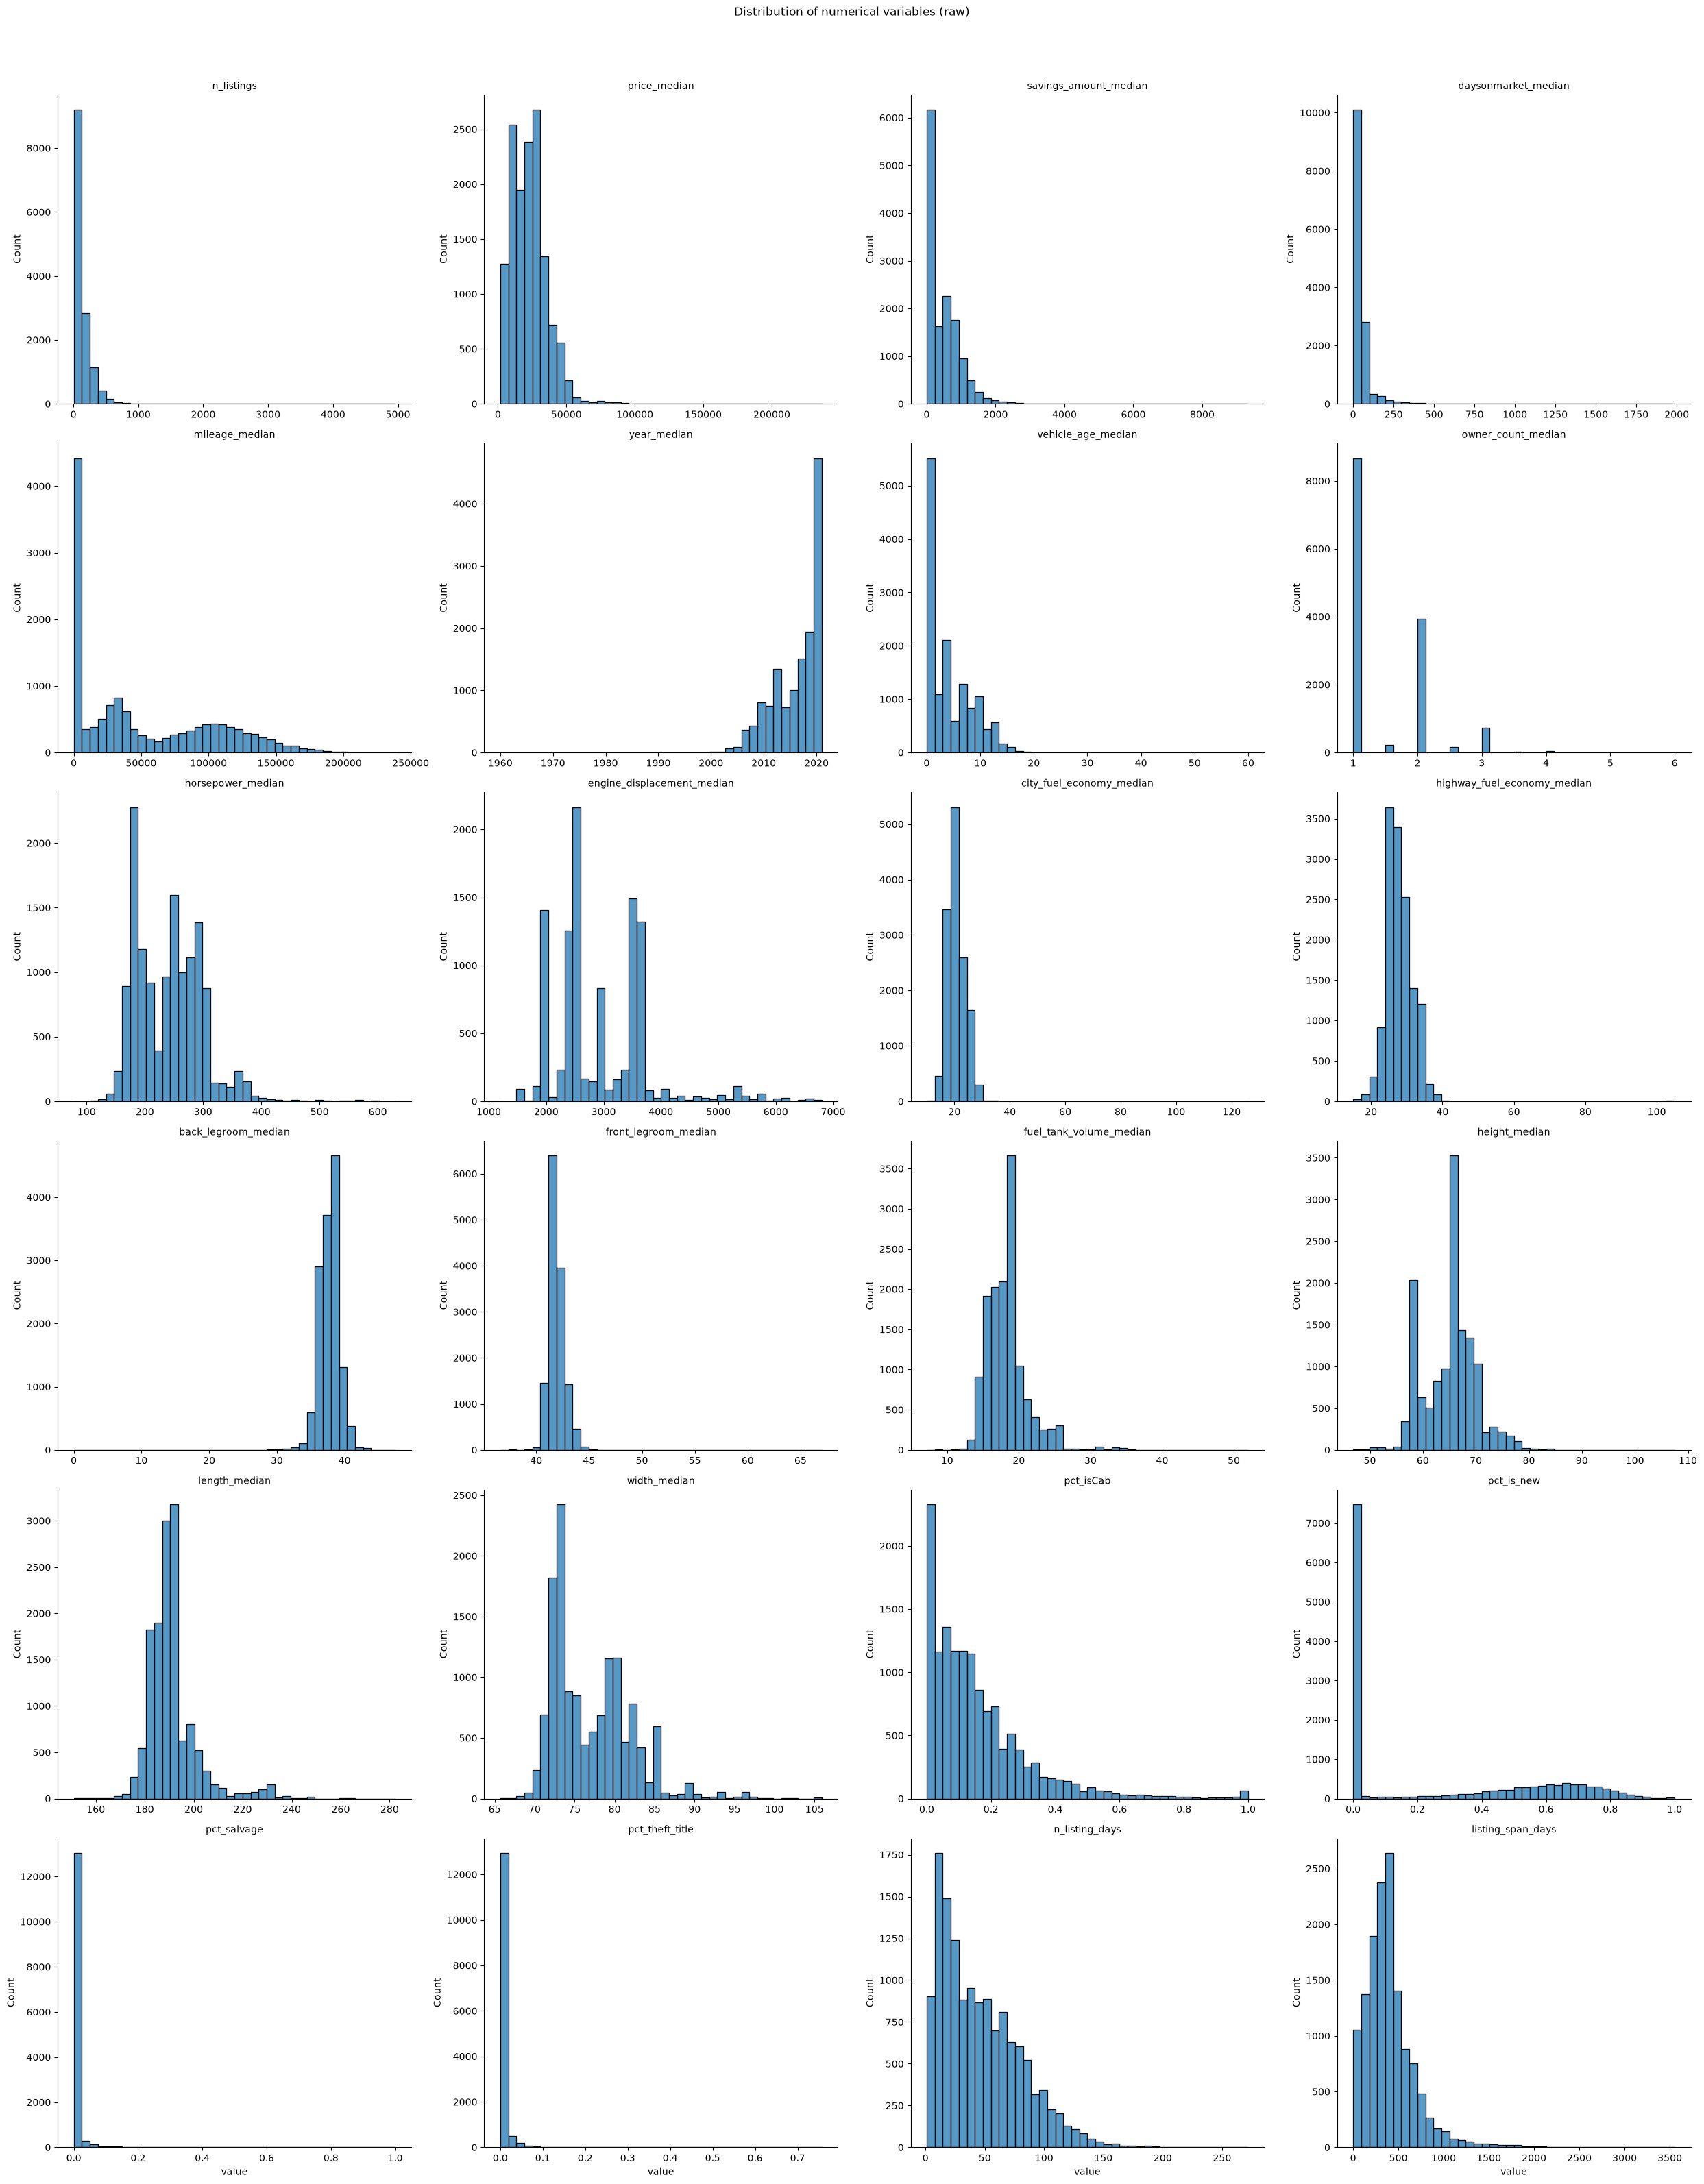

In [17]:
plot_df = df[numerical_cols].melt(var_name='variable', value_name='value')

g = sns.FacetGrid(
    plot_df, col='variable', col_wrap=4,
    sharex=False, sharey=False, height=5.2, aspect=1.2,
)
g.map_dataframe(
    sns.histplot, x='value', bins=40,
)
g.set_titles('{col_name}')
g.figure.suptitle('Distribution of numerical variables (raw)', y=1.02)
plt.tight_layout()
plt.show()

/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

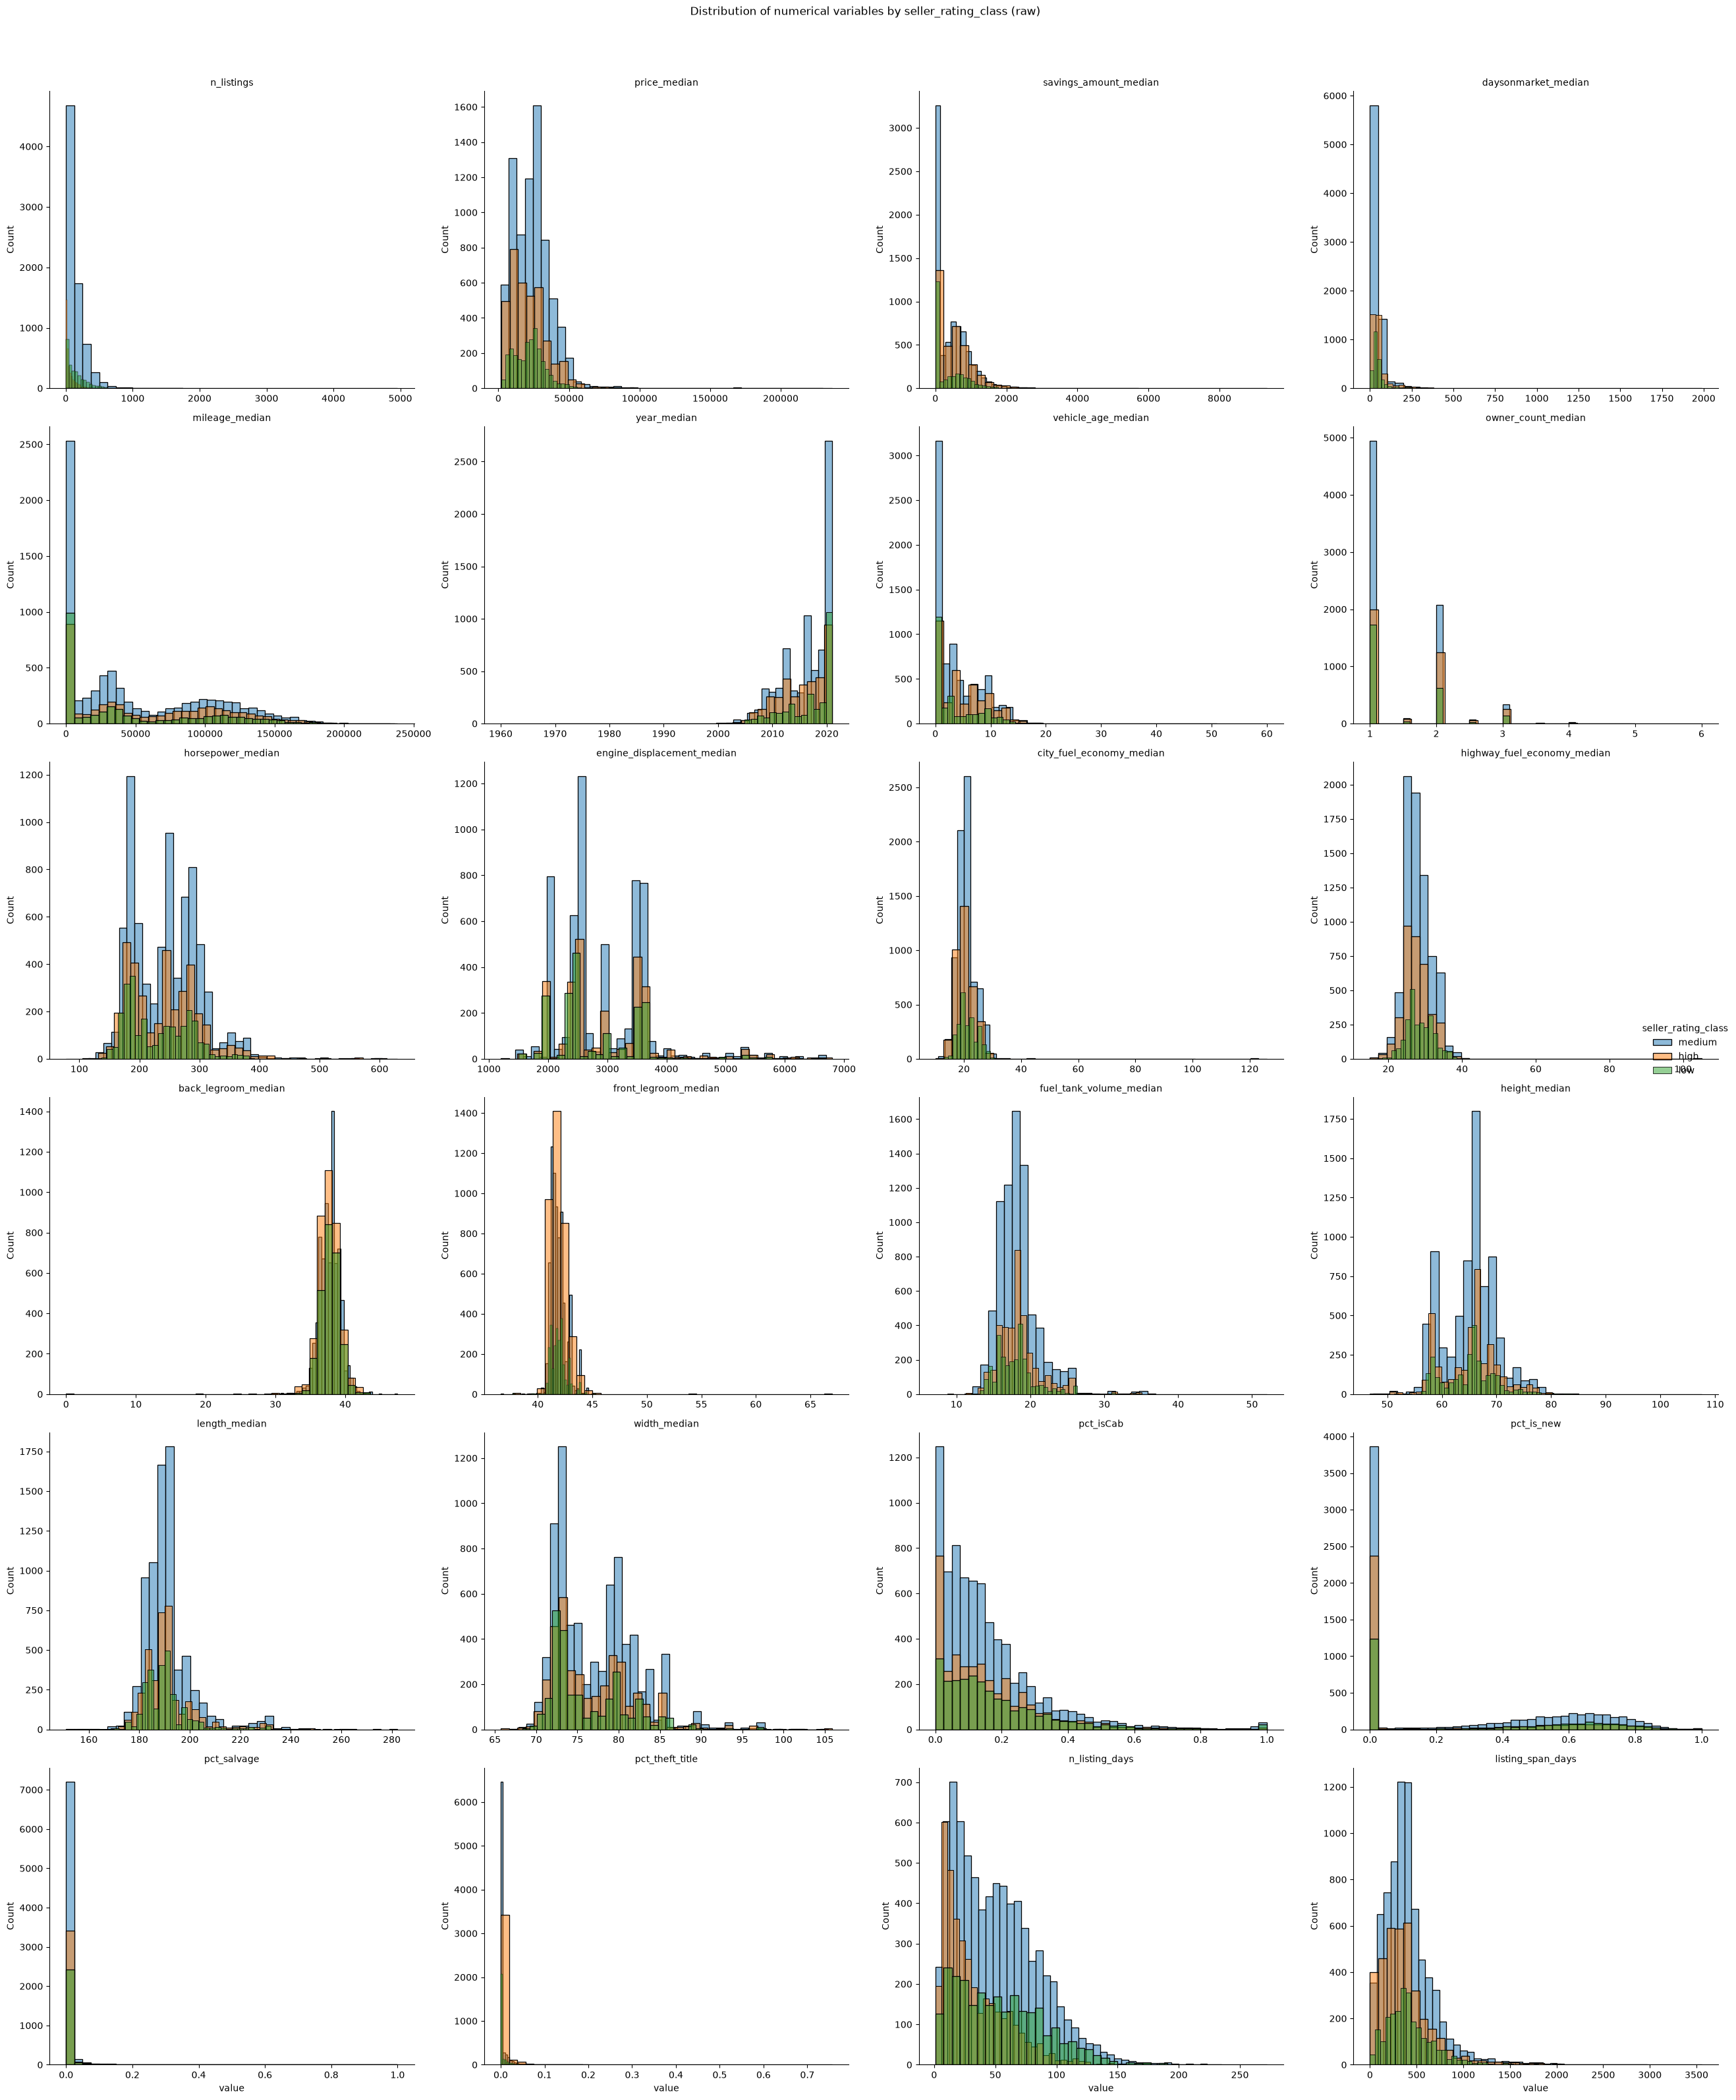

In [18]:
plot_df = df[numerical_cols + ['seller_rating_class']].melt(
    id_vars='seller_rating_class', var_name='variable', value_name='value')

g = sns.FacetGrid(
    plot_df, col='variable', col_wrap=4,
    hue='seller_rating_class', hue_order=['medium', 'high', 'low'],
    sharex=False, sharey=False, height=5.2, aspect=1.2,
)
g.map_dataframe(
    sns.histplot, x='value', bins=40, multiple='layer', alpha=0.5,
    palette={'low': 'tab:red', 'medium': 'tab:blue', 'high': 'tab:green'},
)
g.add_legend(title='seller_rating_class')
g.set_titles('{col_name}')
g.figure.suptitle('Distribution of numerical variables by seller_rating_class (raw)', y=1.02)
plt.tight_layout()
plt.show()

> **Note before moving on:** The numerical distributions above reveal **heavy right skew** and **extreme values (outliers/noise)** in several features (e.g. `price_median`, `daysonmarket_median`, `mileage_median`, `n_listings`, `listing_span_days`, and the `pct_*` proportions).
>
> These are **not fixed here** — they will be handled systematically later:
> - **Outlier / noise handling** → §1.3.2 (cap/winsorize or remove, with justification).
> - **Missing values** → §1.3.1 (drop vs impute).
> - **Log-transform** for strongly skewed features → §1.4.1.
> - **Normalization / scaling** (Z-score) → §1.4.2, required before distance-based methods (k-NN, clustering).


### 1.2.3 Distribution of categorical variables


In [19]:
categorical_cols = [col for col in df.columns if col not in numerical_cols]
categorical_cols.remove('sp_id')
categorical_cols

['dominant_body_type',
 'dominant_fuel_type',
 'dominant_transmission',
 'dominant_wheel_system',
 'dominant_listing_color',
 'franchise_status',
 'new_used_profile',
 'seller_rating_class']

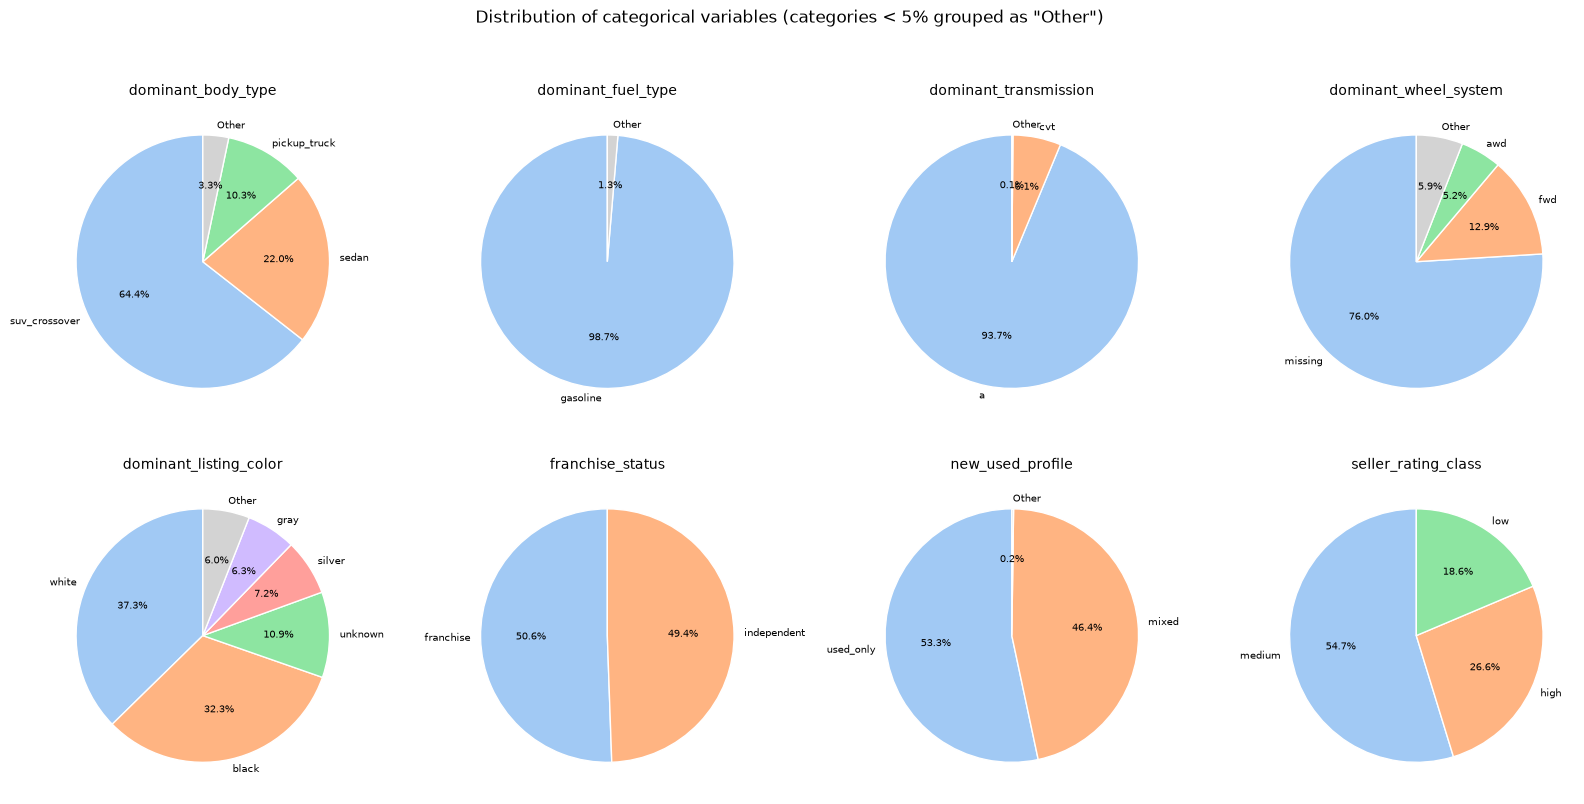

In [20]:
MIN_PCT = 5.0   # Minimum percentage threshold for categories to be displayed in the pie chart

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, col in zip(axes, categorical_cols):
    vc = df[col].value_counts(dropna=False)
    vc.index = [('missing' if pd.isna(i) else i) for i in vc.index]

    pct = vc / vc.sum() * 100
    keep = vc[pct >= MIN_PCT].copy()
    other = vc[pct < MIN_PCT].sum()
    if other > 0:
        keep.loc['Other'] = other

    labels = list(keep.index)
    colors = list(sns.color_palette('pastel', n_colors=len(labels)))
    if 'Other' in labels:
        colors[labels.index('Other')] = 'lightgray'

    ax.pie(
        keep.values,
        labels=labels,
        colors=colors,
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops={'edgecolor': 'white'},
        textprops={'fontsize': 7},
        labeldistance=1.08,
    )
    ax.set_title(col, fontsize=10)

for ax in axes[len(categorical_cols):]:
    ax.axis('off')

plt.suptitle('Distribution of categorical variables (categories < 5% grouped as "Other")', y=1.02)
plt.tight_layout()
plt.show()

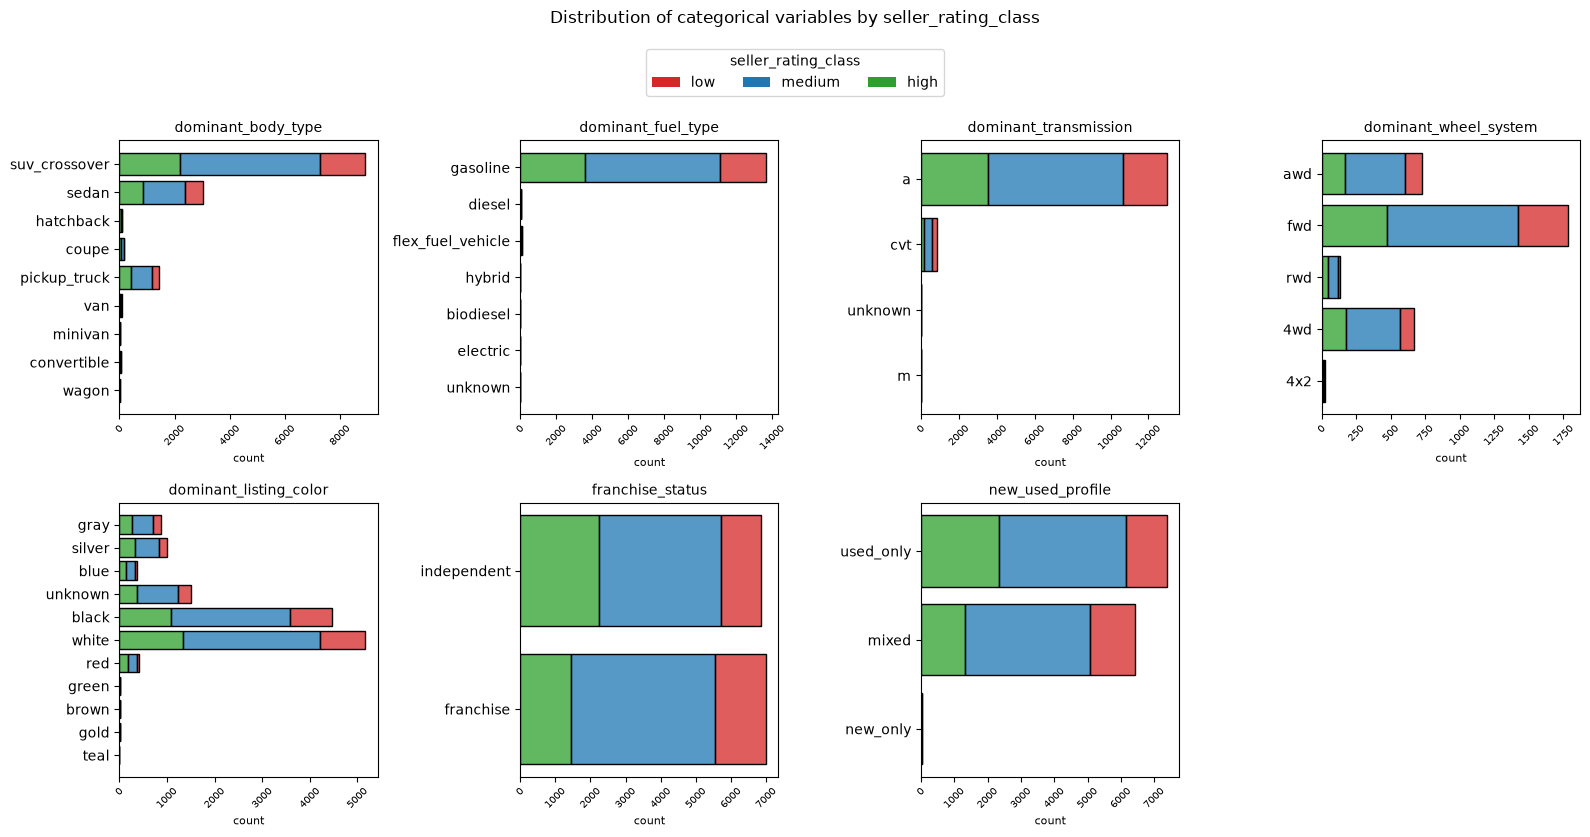

In [21]:
from matplotlib.patches import Patch

hue_order = ['low', 'medium', 'high']
palette = {'low': 'tab:red', 'medium': 'tab:blue', 'high': 'tab:green'}
plot_cols = [c for c in categorical_cols if c != 'seller_rating_class']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, col in zip(axes, plot_cols):
    sns.histplot(
        data=df, y=col,
        hue='seller_rating_class', hue_order=hue_order,
        multiple='stack', palette=palette,
        ax=ax, shrink=0.8, legend=False,
    )
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.set_ylabel('')
    ax.set_xlabel('count', fontsize=8)

for ax in axes[len(plot_cols):]:
    ax.axis('off')

handles = [Patch(facecolor=palette[k], label=k) for k in hue_order]
fig.legend(handles=handles, loc='upper center', ncol=3,
           title='seller_rating_class', bbox_to_anchor=(0.5, 1.0))
plt.suptitle('Distribution of categorical variables by seller_rating_class', y=1.04)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 1.3 Assessment of Data Quality

### 1.3.1 Missing value analysis & imputation strategy

**Checklist:**
- [x] Missing-value heatmap / table (count + %).
- [x] Decide per column: **drop** (too sparse) vs **impute** (median/mode).
- [x] Remember `unknown` is a category, **not** a missing value.
- [x] Justify the rule (e.g. drop if > 50% missing).


In [22]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
missing_df

,missing_count,missing_%
dominant_wheel_system,10518,75.98
engine_displacement_median,3393,24.51
owner_count_median,39,0.28
pct_salvage,27,0.20
pct_theft_title,27,0.20
pct_isCab,27,0.20
back_legroom_median,19,0.14
highway_fuel_economy_median,16,0.12
city_fuel_economy_median,16,0.12
front_legroom_median,7,0.05


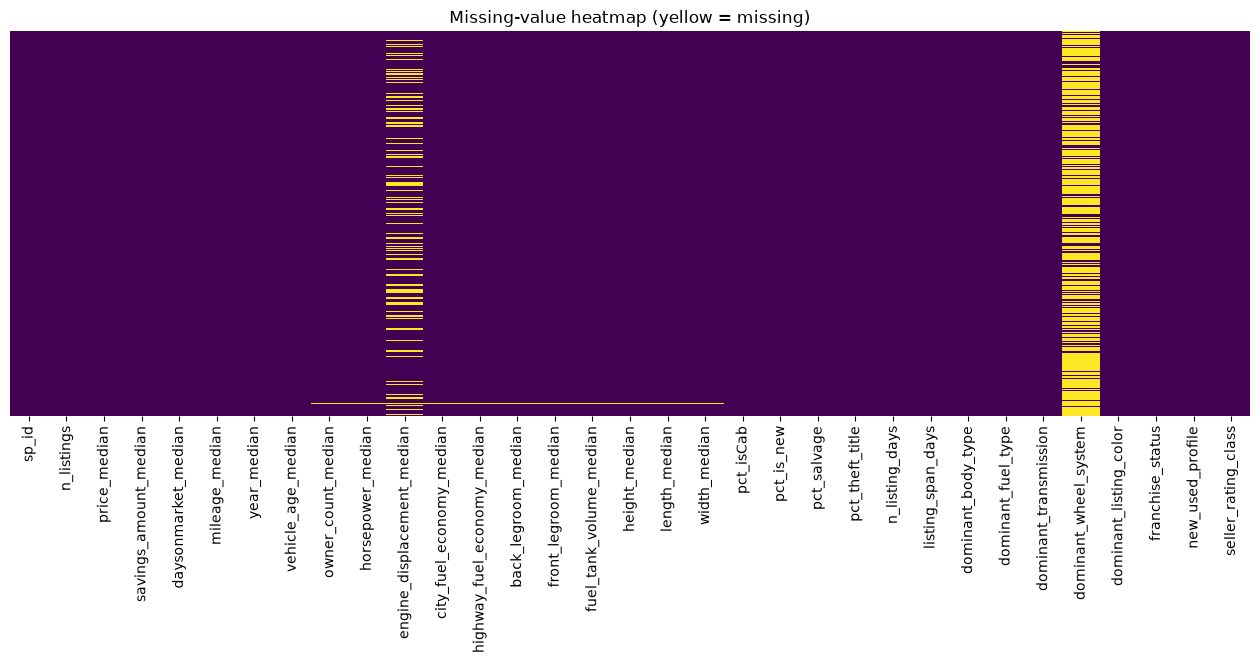

In [23]:
plt.figure(figsize=(16, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing-value heatmap (yellow = missing)')
plt.show()

#### Data Imputation

* `dominant_wheel_system` — **76.0% missing** → too sparse to impute meaningfully; **dropped**.
* `engine_displacement_median` — 24.5% missing → imputed with the **median of similar sellers**
  (same body type and horsepower bin); see below.
* All other numeric columns have < 0.3% missing → **median imputation** (robust to outliers).
* Categorical columns use the label `unknown` rather than `NaN`, so no imputation is needed there.

We also fix the wrong datatypes (`sp_id` → int) and expand the abbreviated transmission labels
(`a` → automatic, `m` → manual).


In [24]:
# Missing-value handling for dominant_wheel_system
df_cleaned = df.copy()

# Convert sp_id to int (it is an identifier, not a measurement)
df_cleaned['sp_id'] = df_cleaned['sp_id'].astype(int)

# Expand transmission abbreviations for readability
df_cleaned['dominant_transmission'] = df_cleaned['dominant_transmission'].replace({
    'a': 'automatic', 'm': 'manual', 'cvt': 'cvt'})

# Drop the near-empty column (76% missing)
df_cleaned.drop(["dominant_wheel_system"], axis=1, inplace=True)


In [25]:
# For engine_displacement_median, we could simply fill the missing values with the
# median/mean/mode of the other rows — but that is not the best we can do.
#
# What is engine_displacement_median? It is the total volume of air-fuel mixture
# swept by the pistons, i.e. the "lung capacity" of the car.
# With this reasoning, the features that should carry similar information are:
# horsepower, city/highway fuel economy, and body type.
# However, city and highway fuel economy represent almost the same information:
print('City vs highway fuel economy correlation:')
print(df['city_fuel_economy_median'].corr(df['highway_fuel_economy_median'], method='spearman'))

# We only need one of them (to avoid redundancy). Now, how do we impute?
#   1. A single mean/mode value      -> easiest, but weakest.
#   2. Group-by on the best anchor   -> better, still simple.
#   3. KNN imputation                -> best, but too complex.
# We use option 2: a good balance between complexity and accuracy.


City vs highway fuel economy correlation:
0.9355868282751701


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

target = 'engine_displacement_median'
cat_anchor = 'dominant_body_type'
num_anchor = 'horsepower_median'

# Evaluate only on rows with an observed target
obs = df_cleaned[df_cleaned[target].notna()].copy()
tr, te = train_test_split(obs, test_size=0.2, random_state=42)

# Bin horsepower on TRAIN, then apply the same edges to TEST
b = pd.qcut(tr[num_anchor], q=5, duplicates='drop').cat.categories
edges = np.unique(np.concatenate([[iv.left for iv in b], [b[-1].right]]))
tr['hp_bin'] = pd.cut(tr[num_anchor], bins=edges, include_lowest=True)
te['hp_bin'] = pd.cut(te[num_anchor], bins=edges, include_lowest=True)

# Group median per (body type, horsepower bin), computed on TRAIN
group_med = tr.groupby([cat_anchor, 'hp_bin'], observed=True)[target].median().to_dict()
base = tr[target].median()

pred = te.apply(lambda r: group_med.get((r[cat_anchor], r['hp_bin']), base), axis=1)

print('MAE groupby (body + hp) :', round(mean_absolute_error(te[target], pred), 1))
print('MAE baseline (median)   :', round(mean_absolute_error(te[target], np.full(len(te), base)), 1))


MAE groupby (body + hp) : 349.3
MAE baseline (median)   : 622.6


In [27]:
# Impute engine_displacement_median with the median of similar sellers:
# same body type AND same horsepower bin. Fall back to the overall median.
hp = df_cleaned[num_anchor].fillna(df_cleaned[num_anchor].median())
df_cleaned['hp_bin'] = pd.cut(hp, bins=edges, include_lowest=True)

# Group medians computed only from rows that still have an observed target
group_med_full = (
    df_cleaned[df_cleaned[target].notna()]
    .groupby([cat_anchor, 'hp_bin'], observed=True)[target]
    .median()
    .to_dict()
)
overall_med = df_cleaned[target].median()

miss = df_cleaned[target].isna()
keys = list(zip(df_cleaned[cat_anchor], df_cleaned['hp_bin']))
preds = pd.Series([group_med_full.get(k, overall_med) for k in keys], index=df_cleaned.index)

df_cleaned.loc[miss, target] = preds[miss]

# Drop the temporary helper column
df_cleaned.drop(columns=['hp_bin'], inplace=True, errors='ignore')

print('missing before:', miss.sum())
print('missing after :', df_cleaned[target].isna().sum())


missing before: 3393
missing after : 0


In [28]:
# pct_salvage is zero-inflated (91% zeros), so qcut cannot build equal-frequency bins.
# Use fixed, meaningful bins instead.
pd.cut(
    df_cleaned['pct_salvage'],
    bins=[-0.001, 0, 0.05, 0.10, 1.0],
    labels=['0', '0-5%', '5-10%', '>10%'],
).value_counts(dropna=False).sort_index()


pct_salvage
0        12574
0-5%       759
5-10%      202
>10%       281
NaN         27
Name: count, dtype: int64

In [29]:
# Same idea for pct_theft_title: zero-inflated, so use fixed bins instead of qcut.
pd.cut(
    df_cleaned['pct_theft_title'],
    bins=[-0.001, 0, 0.05, 0.10, 1.0],
    labels=['0', '0-5%', '5-10%', '>10%'],
).value_counts(dropna=False).sort_index()


pct_theft_title
0        11706
0-5%      1883
5-10%      167
>10%        60
NaN         27
Name: count, dtype: int64

### 1.3.2 Outlier and noise detection (boxplots, semantic checks & filtering)

**Checklist:**
- [x] Boxplots for the numeric features.
- [x] Use **both** a statistical rule (IQR) **and** domain rules (impossible values).
- [x] Decide per feature: **drop**, **cap/winsorize**, or **keep** (justify).
- [x] Inspect the flagged rows (`df.query(...)`) before deciding.


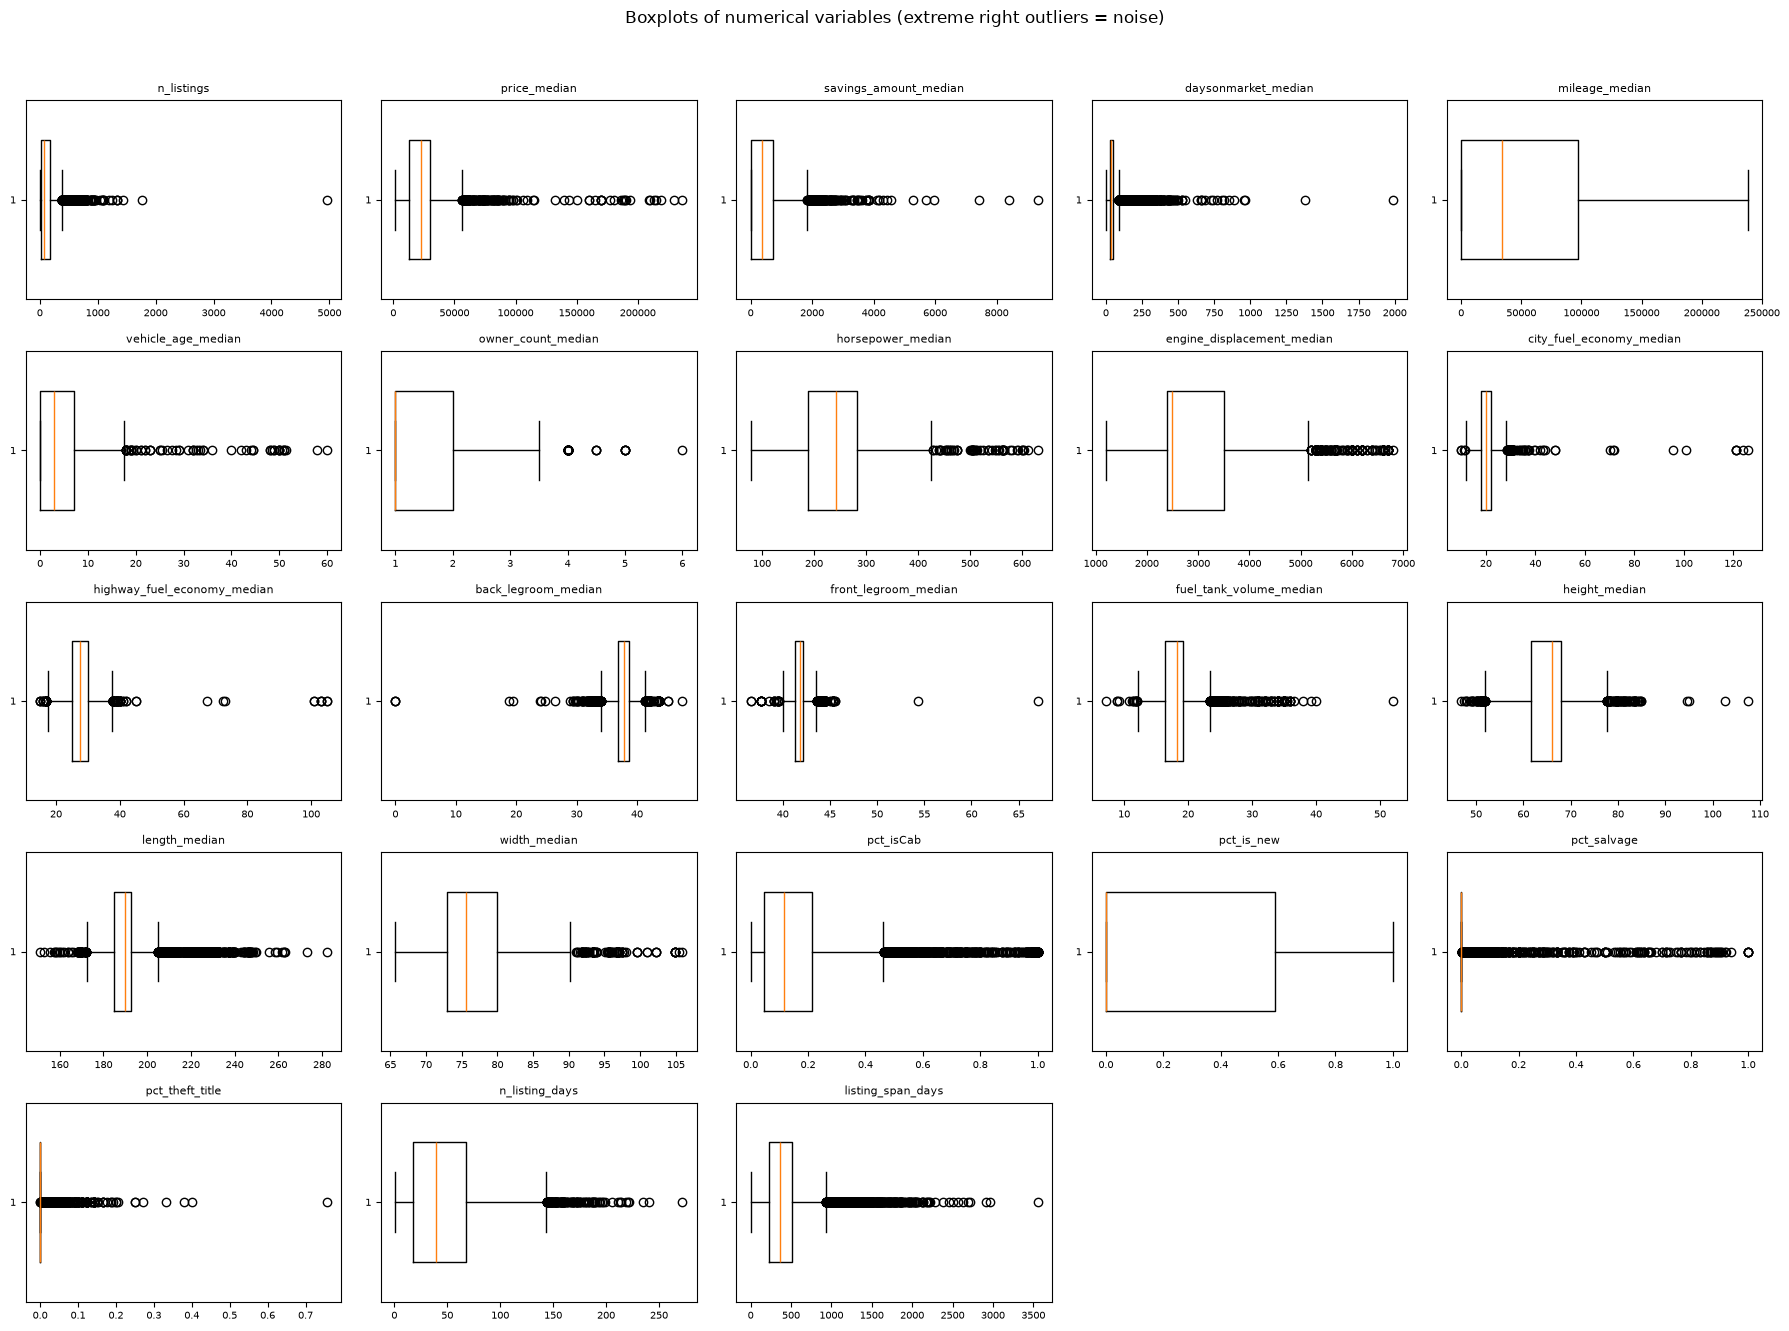

In [30]:
# Boxplots reveal the severe right tails / injected noise
cont = [c for c in numerical_cols if c != 'year_median']
ncols = 5
nrows = int(np.ceil(len(cont) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 2.6))
axes = axes.ravel()
for ax, col in zip(axes, cont):
    ax.boxplot(df[col].dropna(), orientation='horizontal', widths=0.6)
    ax.set_title(col, fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes[len(cont):]:
    ax.axis('off')
plt.suptitle('Boxplots of numerical variables (extreme right outliers = noise)', y=1.02)
plt.tight_layout()
plt.show()

In [31]:
# --- Step 1: semantic fix (impossible value) ---------------------------------
n_bad = (df_cleaned['back_legroom_median'] == 0).sum()
df_cleaned.loc[df_cleaned['back_legroom_median'] == 0, 'back_legroom_median'] = np.nan
print(f'back_legroom_median == 0 (impossible) fixed: {n_bad} rows -> NaN')

# --- Step 2: winsorize the heavy-tailed continuous features ------------------
winsorize_cols = [
    'n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median',
    'mileage_median', 'vehicle_age_median', 'horsepower_median',
    'engine_displacement_median', 'city_fuel_economy_median', 'highway_fuel_economy_median',
    'back_legroom_median', 'front_legroom_median', 'fuel_tank_volume_median',
    'height_median', 'length_median', 'width_median', 'n_listing_days', 'listing_span_days',
]
# owner_count (discrete 1-6) and the proportions (already in [0,1]) are excluded.

winsor_bounds = {}
for col in winsorize_cols:
    upper = df_cleaned[col].quantile(0.99)
    winsor_bounds[col] = upper
    df_cleaned[col] = df_cleaned[col].clip(upper=upper)

print('\nWinsorization upper bounds (99th percentile):')
for col, upper in winsor_bounds.items():
    print(f'  {col:30s} -> {upper:10.2f}')


back_legroom_median == 0 (impossible) fixed: 3 rows -> NaN

Winsorization upper bounds (99th percentile):
  n_listings                     ->     572.48
  price_median                   ->   59920.57
  savings_amount_median          ->    2086.22
  daysonmarket_median            ->     280.00
  mileage_median                 ->  174295.00
  vehicle_age_median             ->      15.00
  horsepower_median              ->     385.00
  engine_displacement_median     ->    5700.00
  city_fuel_economy_median       ->      28.00
  highway_fuel_economy_median    ->      37.00
  back_legroom_median            ->      41.20
  front_legroom_median           ->      43.90
  fuel_tank_volume_median        ->      28.00
  height_median                  ->      77.50
  length_median                  ->     231.83
  width_median                   ->      93.40
  n_listing_days                 ->     142.00
  listing_span_days              ->    1493.58


In [32]:
# Impute numeric missings with the (now robust) median
for col in df_cleaned.select_dtypes(include=[np.number]).columns:
    if df_cleaned[col].isna().any():
        med = df_cleaned[col].median()
        df_cleaned[col] = df_cleaned[col].fillna(med)
        print(f'  imputed {col:30s} median = {med:10.2f}')

print('\nMissing values remaining:', df_cleaned.isna().sum().sum())
print('\nsp_id dtype:', df_cleaned['sp_id'].dtype)


  imputed mileage_median                 median =   33596.50
  imputed vehicle_age_median             median =       3.00
  imputed owner_count_median             median =       1.00
  imputed horsepower_median              median =     243.00
  imputed city_fuel_economy_median       median =      20.00
  imputed highway_fuel_economy_median    median =      27.50
  imputed back_legroom_median            median =      37.80
  imputed front_legroom_median           median =      41.80
  imputed fuel_tank_volume_median        median =      18.25
  imputed height_median                  median =      66.00
  imputed length_median                  median =     189.80
  imputed width_median                   median =      75.55
  imputed pct_isCab                      median =       0.12
  imputed pct_salvage                    median =       0.00
  imputed pct_theft_title                median =       0.00

Missing values remaining: 0

sp_id dtype: int64


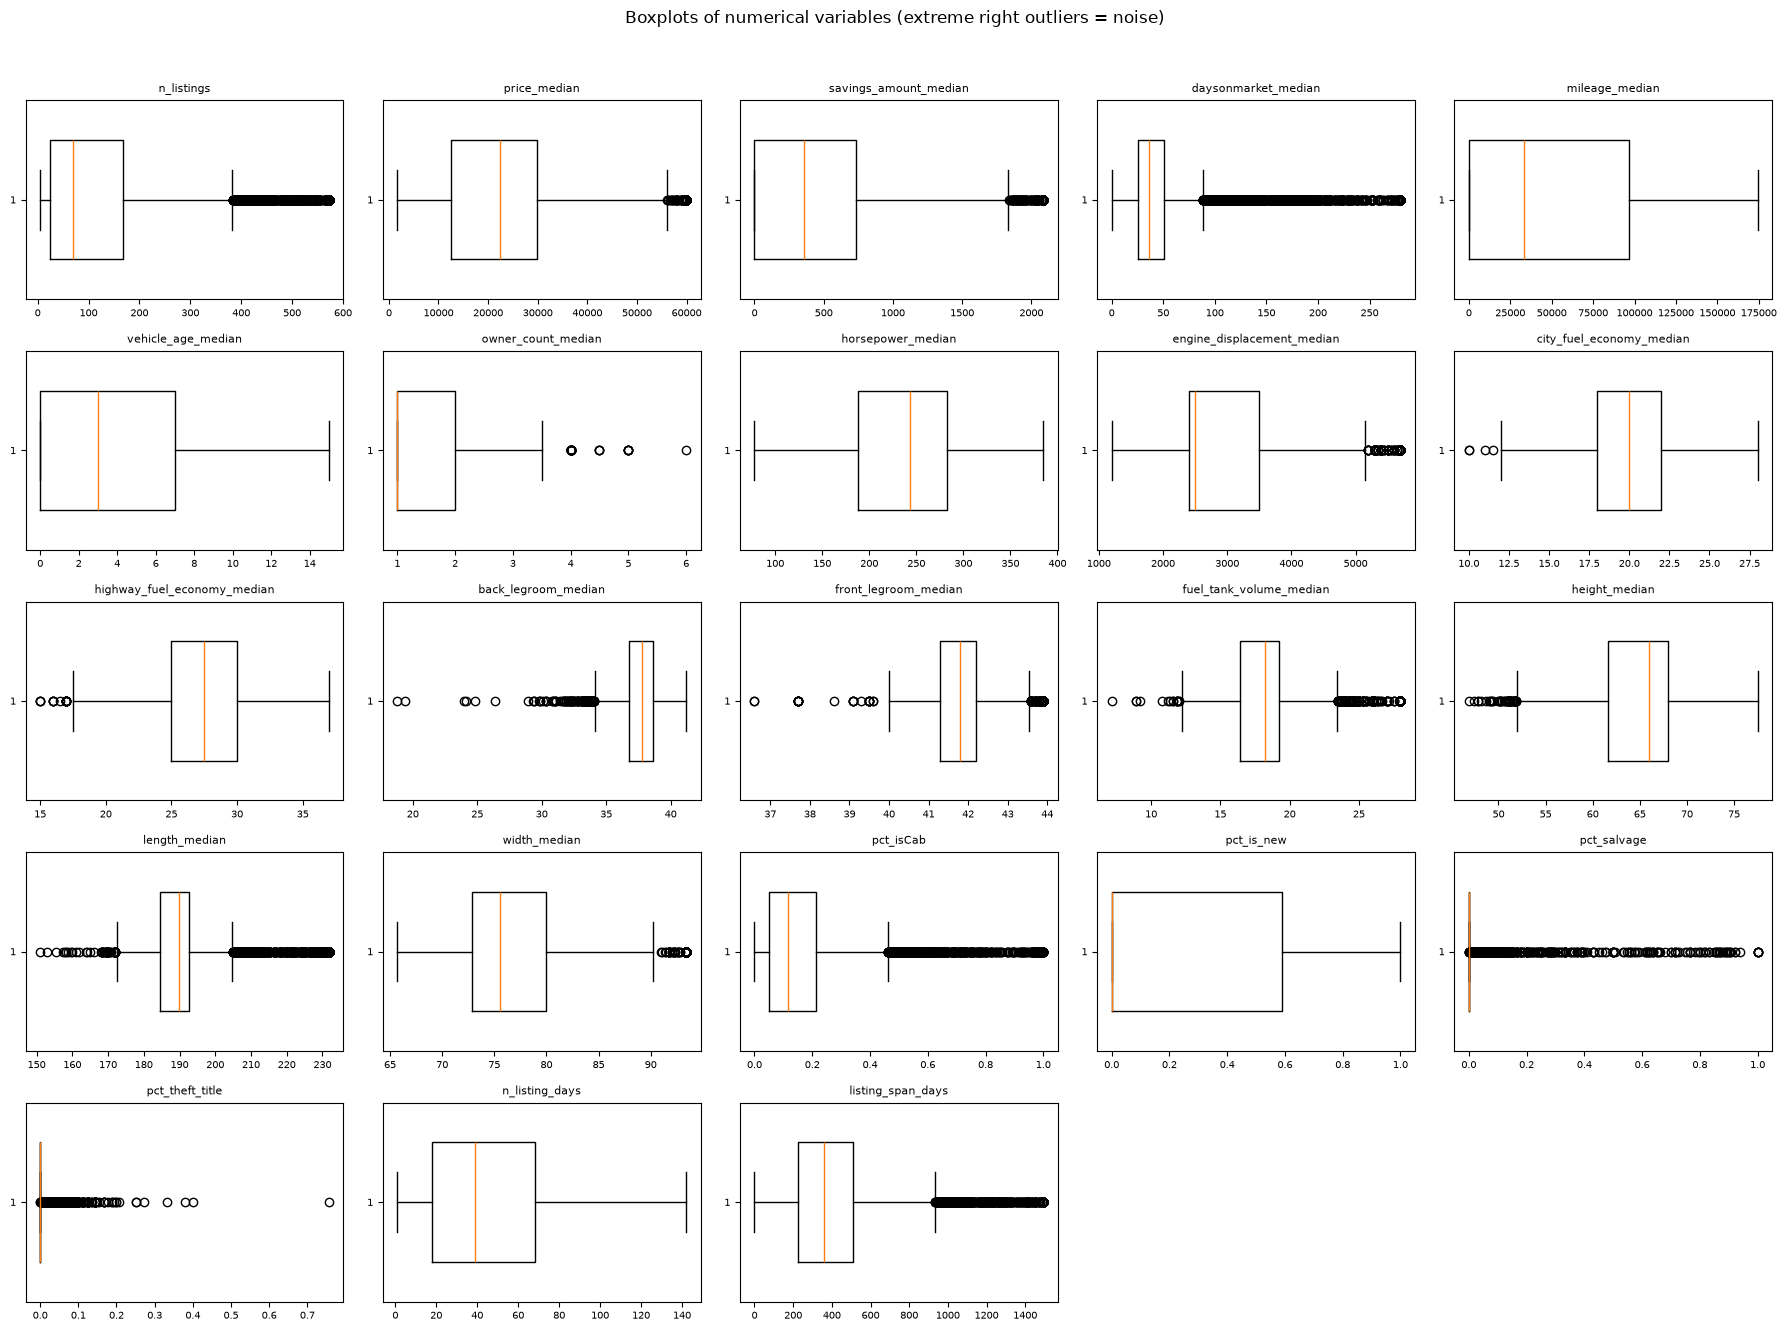

In [33]:
# Boxplots reveal the severe right tails / injected noise
cont = [c for c in numerical_cols if c != 'year_median']
ncols = 5
nrows = int(np.ceil(len(cont) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 2.6))
axes = axes.ravel()
for ax, col in zip(axes, cont):
    ax.boxplot(df_cleaned[col].dropna(), orientation='horizontal', widths=0.6)
    ax.set_title(col, fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes[len(cont):]:
    ax.axis('off')
plt.suptitle('Boxplots of numerical variables (extreme right outliers = noise)', y=1.02)
plt.tight_layout()
plt.show()

## 1.4 Variables Transformation

### 1.4.1 Log-transformation for highly skewed variables

**Checklist:**
- [x] Pick features with skewness > 1 (from §1.2.2).
- [x] Apply `np.log1p` and compare skewness before/after.


In [34]:
num_clean = df_cleaned.select_dtypes(include=[np.number]).drop(columns=['sp_id']).columns.tolist()
skew_before = df_cleaned[num_clean].skew()

# log-transform the highly right-skewed continuous features (skip the discrete owner count)
highly_skewed = [c for c in num_clean if skew_before[c] > 1 and c != 'owner_count_median']
print('Features with skew > 1 (log1p-transformed):')
print(highly_skewed)

df_log = df_cleaned.copy()
for col in highly_skewed:
    df_log[col] = np.log1p(df_log[col])

compare = pd.DataFrame({'skew_before': skew_before, 'skew_after_log1p': df_log[num_clean].skew()})
compare.loc[highly_skewed].round(2)


Features with skew > 1 (log1p-transformed):
['n_listings', 'savings_amount_median', 'daysonmarket_median', 'engine_displacement_median', 'fuel_tank_volume_median', 'length_median', 'pct_isCab', 'pct_salvage', 'pct_theft_title', 'listing_span_days']


,skew_before,skew_after_log1p
n_listings,1.62,-0.16
savings_amount_median,1.06,-0.41
daysonmarket_median,3.31,0.29
engine_displacement_median,1.07,0.33
fuel_tank_volume_median,1.07,0.54
length_median,1.90,1.62
pct_isCab,2.04,1.47
pct_salvage,10.35,9.33
pct_theft_title,14.12,10.64
listing_span_days,1.49,-1.27


### 1.4.2 Feature scaling (Z-score / Min-Max)

**Checklist:**
- [x] Choose **Z-score** vs **Min-Max** and justify (outliers? bounded range?).
- [x] Scale the numeric features.
- [x] Encode categorical features (one-hot) if needed for distance-based models.


In [35]:
scaler = StandardScaler()
df_scaled = df_log.copy()
df_scaled[num_clean] = scaler.fit_transform(df_log[num_clean])

print('After Z-score (numeric features):')
df_scaled[num_clean].describe().T.round(3)


After Z-score (numeric features):


,count,mean,std,min,25%,50%,75%,max
n_listings,13843.0,-0.0,1.0,-2.085,-0.809,0.065,0.819,1.882
price_median,13843.0,-0.0,1.0,-1.742,-0.848,-0.029,0.592,3.078
savings_amount_median,13843.0,-0.0,1.0,-1.267,-1.267,0.619,0.848,1.183
daysonmarket_median,13843.0,0.0,1.0,-5.810,-0.582,-0.082,0.458,3.134
mileage_median,13843.0,-0.0,1.0,-0.997,-0.996,-0.344,0.885,2.387
year_median,13843.0,-0.0,1.0,-11.849,-0.625,0.223,0.858,1.070
vehicle_age_median,13843.0,-0.0,1.0,-0.960,-0.960,-0.239,0.722,2.645
owner_count_median,13843.0,0.0,1.0,-0.694,-0.694,-0.694,0.911,7.330
horsepower_median,13843.0,0.0,1.0,-2.984,-0.960,0.051,0.787,2.663
engine_displacement_median,13843.0,0.0,1.0,-3.580,-0.694,-0.524,0.877,2.908


In [36]:
# One-hot encode categorical features (target and id are left untouched)
cat_features = [
    'dominant_body_type', 'dominant_fuel_type', 'dominant_transmission',
    'dominant_listing_color', 'franchise_status', 'new_used_profile',
]
df_encoded = pd.get_dummies(df_scaled, columns=cat_features, dtype=int)
print('One-hot encoded shape:', df_encoded.shape)
df_encoded.head()


One-hot encoded shape: (13843, 62)


,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,...,dominant_listing_color_red,dominant_listing_color_silver,dominant_listing_color_teal,dominant_listing_color_unknown,dominant_listing_color_white,franchise_status_franchise,franchise_status_independent,new_used_profile_mixed,new_used_profile_new_only,new_used_profile_used_only
0,404771,-0.656335,-1.327990,0.677947,-1.623858,2.386775,-1.048116,1.202649,0.910944,0.336261,...,0,0,0,0,0,0,1,0,0,1
1,336590,-1.129271,-0.972394,0.728619,-0.704047,0.703680,-0.836342,0.722030,0.910944,-1.070835,...,0,1,0,0,0,0,1,0,0,1
2,392016,-1.082233,-1.249750,0.800387,0.192754,1.943008,-1.154003,1.322804,0.910944,-0.647787,...,0,0,0,0,0,0,1,0,0,1
3,294197,-1.412383,0.058711,0.711713,-1.139408,-0.391189,0.222529,-0.239207,-0.693917,-1.144409,...,0,0,0,1,0,1,0,0,0,1
4,372085,-1.287888,-1.138394,0.728936,2.702064,1.807856,-1.789326,1.923577,0.108513,-0.004017,...,0,1,0,0,0,0,1,0,0,1


## 1.5 Pairwise Correlations and Variable Elimination

### 1.5.1 Pairwise scatter plot matrix

**Checklist:**
- [x] Scatter matrix / pairplot of the main numeric features.
- [x] Note non-linear relationships and clusters.


#### Why these six variables? (pairwise scatter matrix)

A full scatter matrix over all ~25 numeric features would produce 25×25 ≈ 625
panels — unreadable and slow. We therefore use a **representative subset** that
covers the main dimensions of the data instead of every column.

| Variable | Dimension it represents |
|---|---|
| `price_median` | **Economic value** — the advertised price |
| `mileage_median` | **Usage / wear** — how much the vehicles were driven |
| `vehicle_age_median` | **Vehicle age** — listing year minus model year |
| `horsepower_median` | **Performance / engine** |
| `n_listings` | **Seller size** — the strongest single predictor of the rating target |
| `city_fuel_economy_median` | **Efficiency / vehicle type** |

The set spans price, usage, age, engine, seller scale and efficiency, while
avoiding near-duplicates (`highway_fuel_economy` ≈ `city_fuel_economy`, ρ = 0.94;
`year_median` ≈ `vehicle_age_median`, ρ = −0.98).

**What we look for in the matrix:**
- direction of relationships (price ↔ mileage should be negative; mileage ↔ age positive);
- linear vs non-linear patterns (motivates the log transform);
- clusters (e.g. new vs old vehicles);
- near-collinear pairs (straight lines → candidates for elimination);
- outliers.

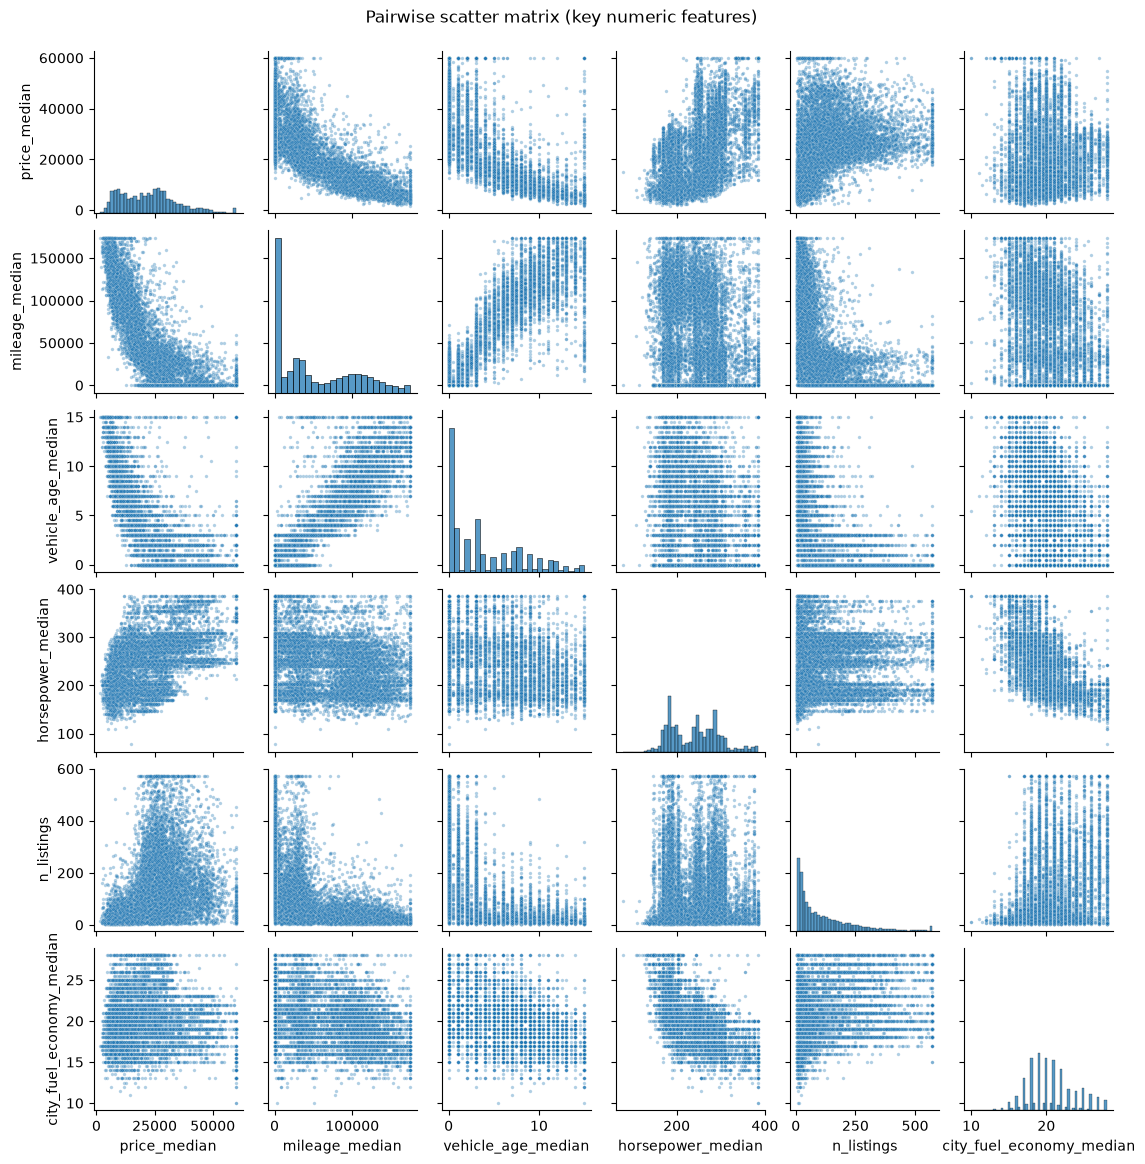

In [37]:
# Pairwise scatter matrix of a few representative numeric features
key = ['price_median', 'mileage_median', 'vehicle_age_median', 'horsepower_median',
       'n_listings', 'city_fuel_economy_median']
sns.pairplot(df_cleaned[key], height=1.9, plot_kws={'s': 6, 'alpha': 0.35})
plt.suptitle('Pairwise scatter matrix (key numeric features)', y=1.02)
plt.show()


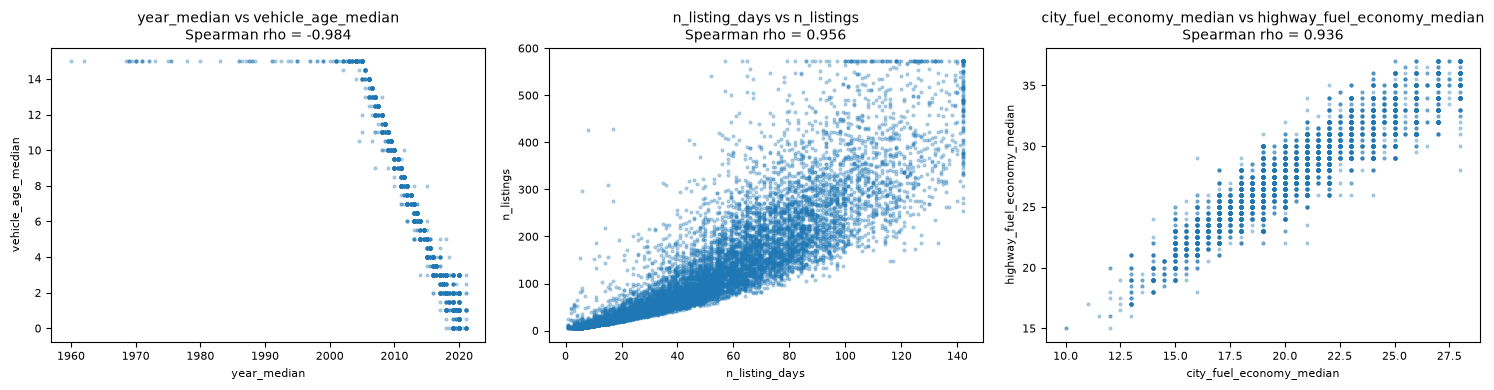

In [38]:
# Scatter plots confirming the near-duplicate pairs
dup_pairs = [
    ('year_median', 'vehicle_age_median'),
    ('n_listing_days', 'n_listings'),
    ('city_fuel_economy_median', 'highway_fuel_economy_median'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (x, y) in zip(axes, dup_pairs):
    ax.scatter(df_cleaned[x], df_cleaned[y], s=4, alpha=0.3)
    rho = df_cleaned[x].corr(df_cleaned[y], method='spearman')
    ax.set_title(f'{x} vs {y}\nSpearman rho = {rho:.3f}', fontsize=10)
    ax.set_xlabel(x, fontsize=8)
    ax.set_ylabel(y, fontsize=8)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()


### 1.5.2 Spearman correlation matrix heatmap & redundant feature elimination

**Checklist:**
- [x] Spearman correlation heatmap (robust to skew and outliers).
- [x] List pairs with |rho| above a threshold (e.g. 0.9).
- [x] Decide which redundant feature to drop and justify.


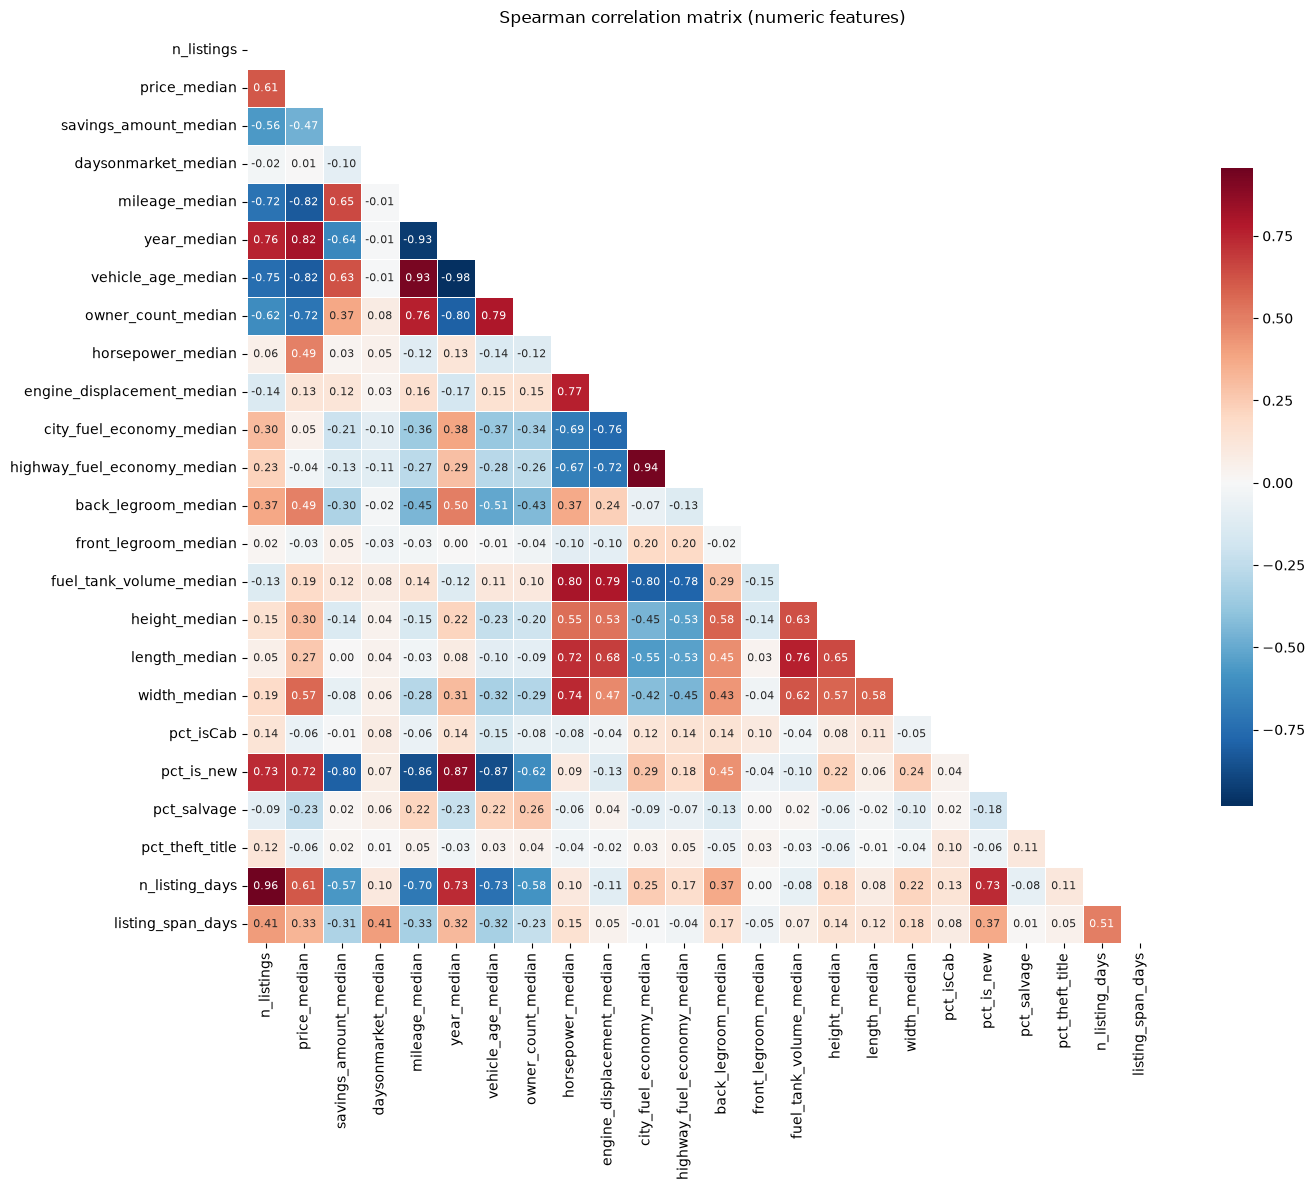

In [39]:
corr = df_cleaned[num_clean].corr(method='spearman')

plt.figure(figsize=(15, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.7}, annot_kws={"fontsize":8})
plt.title('Spearman correlation matrix (numeric features)')
plt.tight_layout()
plt.show()


In [40]:
# List the strongest correlated pairs (|rho| > 0.8)
pairs = []
cols = corr.columns.tolist()
for i in range(len(cols)):
    for j in range(i):
        r = corr.iloc[i, j]
        if abs(r) > 0.8:
            pairs.append((cols[i], cols[j], round(r, 3)))
pairs = sorted(pairs, key=lambda x: -abs(x[2]))
print('Pairs with |rho| > 0.8:')
for a, b, r in pairs:
    print(f'  {a:28s} vs {b:28s}  rho = {r:+.3f}')


Pairs with |rho| > 0.8:
  vehicle_age_median           vs year_median                   rho = -0.984
  n_listing_days               vs n_listings                    rho = +0.956
  highway_fuel_economy_median  vs city_fuel_economy_median      rho = +0.936
  year_median                  vs mileage_median                rho = -0.932
  vehicle_age_median           vs mileage_median                rho = +0.927
  pct_is_new                   vs year_median                   rho = +0.873
  pct_is_new                   vs vehicle_age_median            rho = -0.867
  pct_is_new                   vs mileage_median                rho = -0.861
  mileage_median               vs price_median                  rho = -0.823
  year_median                  vs price_median                  rho = +0.820
  vehicle_age_median           vs price_median                  rho = -0.815
  fuel_tank_volume_median      vs horsepower_median             rho = +0.805


**Variable elimination.**

There's no variable that will be eliminated in this stage, because we need to preserve the data to be consumed for the next algorithms / task.

## 2. Export the final dataset

The cleaned dataset is exported for the next steps (clustering / classification /
regression / pattern mining). Redundant features are **kept** at this stage and will
be eliminated per-task, so no information is lost.


In [41]:
# Export the final cleaned dataset for the next steps
output_path = 'dataset/seller_info_dm1_2627_clean.csv'
df_cleaned.to_csv(output_path, index=False)

print(f'Saved to : {output_path}')
print(f'Shape    : {df_cleaned.shape[0]:,} rows x {df_cleaned.shape[1]} columns')
print(f'Nulls    : {df_cleaned.isna().sum().sum()}')


Saved to : dataset/seller_info_dm1_2627_clean.csv
Shape    : 13,843 rows x 32 columns
Nulls    : 0
